# Laboratorium 02: klasyfikacja na danych Adult Census Income

## Wstęp

Celem laboratorium jest zbudowanie modelu przewidującego, czy **roczny dochód osoby przekracza 50 tys. USD**, na podstawie danych ze spisu ludności USA: wieku, wykształcenia, zawodu, stanu cywilnego, liczby przepracowanych godzin i kilku innych cech. To jeden z najbardziej znanych zbiorów do klasyfikacji, a jednocześnie dobry przykład problemów, które spotyka się w prawdziwych danych: duplikatów, braków, które same niosą informację i cech wrażliwych (płeć, rasa).

### Plan:

1. EDA
2. metryki klasyfikacji i model bazowy
3. regresja logistyczna z przetwarzaniem danych w potoku (`Pipeline`)
4. drzewa decyzyjne, Random Forest i boosting (LightGBM)
5. dobór progu decyzyjnego i kalibrację prawdopodobieństw
6. ważność cech

### Uwagi

- kod uzupełniasz w miejscach oznaczonych `# TODO`.
- pod większością zadań znajdują się asercje (`assert`), które pomogą Ci sprawdzić rozwiązanie. 
- część zadań wymaga odpowiedzi pisemnej w komórce oznaczonej **Odpowiedź:**, 2–4 zdania wystarczą.
- pamiętaj o tytułach i opisach osi na wykresach.
- nie zmieniaj nazw zmiennych, z których korzystają asercje i kolejne zadania.
- część obliczeń (strojenie hiperparametrów, walidacja skrośna) trwa od kilkunastu sekund do 2 minut na zwykłym laptopie.

## Część 1. Konfiguracja środowiska z `uv`

Konfiguracja wygląda tak samo jak w laboratorium 1. Projekt jest **już przygotowany** - `pyproject.toml` i `uv.lock` są w repozytorium, wystarczy odtworzyć środowisko:

```bash
cd lab02_klasyfikacja
uv sync
uv run jupyter lab
```

Jeżeli nie masz jeszcze `uv`, zainstaluj go zgodnie z [dokumentacją](https://docs.astral.sh/uv/getting-started/installation/).

W porównaniu z laboratorium 1 dochodzi biblioteka [LightGBM](https://lightgbm.readthedocs.io/en/stable/) - bardzo wydajna implementacja gradient boostingu.

### Dane

Plik `data/adult.csv` to zbiór [Adult](https://archive.ics.uci.edu/dataset/2/adult) z UCI Machine Learning Repository (B. Becker, R. Kohavi, 1996, licencja CC BY 4.0) - połączone oryginalne pliki `adult.data` i `adult.test`. Dane pochodzą ze spisu ludności USA z 1994 roku. Plik nie ma nagłówka, a braki zapisano jako `?`.

### Google Colab

Jeżeli pracujesz w Colabie, prześlij do katalogu `/content` plik `adult.csv` oraz `requirements.txt`, zmień ścieżkę `DATA_PATH` poniżej i odkomentuj komórkę z instalacją. Po instalacji zrestartuj sesję (*Runtime → Restart session*).

In [ ]:
# odkomentuj i uruchom, jeżeli korzystasz z Google Colab
# !pip install -r requirements.txt

### Importy i konfiguracja

Tak jak poprzednio ustawiamy globalnie `transform_output="pandas"`, dzięki czemu transformatory scikit-learn zwracają `DataFrame` z nazwami kolumn.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

sklearn.set_config(transform_output="pandas")
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 0
DATA_PATH = "data/adult.csv"  # w Colabie: "/content/adult.csv"

COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income",
]
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS, na_values="?", skipinitialspace=True)

## Część 2. Eksploracyjna analiza danych

| Kolumna | Opis |
|---|---|
| `age` | wiek |
| `workclass` | sektor zatrudnienia (prywatny, samozatrudnienie, administracja itd.) |
| `fnlwgt` | *final weight* - waga obserwacji w próbie spisowej: ile osób w populacji „reprezentuje” ten wiersz |
| `education`, `education-num` | wykształcenie jako tekst i jako numer poziomu (1–16) |
| `marital-status` | stan cywilny |
| `occupation` | zawód |
| `relationship` | rola w gospodarstwie domowym (`Husband`, `Wife`, `Own-child`, ...) |
| `race`, `sex` | rasa i płeć |
| `capital-gain`, `capital-loss` | zyski i straty kapitałowe w USD |
| `hours-per-week` | liczba godzin pracy w tygodniu |
| `native-country` | kraj pochodzenia |
| `income` | **dochód `<=50K` lub `>50K` (zmienna docelowa)** |

**Uwaga o `fnlwgt`.** Osoby o podobnych cechach demograficznych powinny mieć podobne wagi, ale tylko w obrębie jednego stanu. Ankieta CPS z 1994 r., z której pochodzą dane, to w praktyce 51 osobnych prób, każda z własnym prawdopodobieństwem wylosowania: w małym stanie jeden ankietowany reprezentuje mniej osób niż w dużym. Żadnej z tych zmiennych nie ma w zbiorze, dlatego dwie osoby o identycznych cechach mogą mieć różne `fnlwgt`.

In [2]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


### Klasyfikacja

W laboratorium 1 przewidywaliśmy wartość ciągłą - cenę - czyli rozwiązywaliśmy problem **regresji**. Teraz mamy **klasyfikację**: skończony zbiór **klas**, a model ma nauczyć się je od siebie odróżniać. Wyróżniamy:
- **klasyfikację binarną** - dokładnie 2 klasy, oznaczane 0/1 albo negatywna/pozytywna. Klasa pozytywna to zwykle zjawisko, które chcemy wykryć (u nas: dochód `>50K`),
- **klasyfikację wieloklasową** - 3 lub więcej klas.

Model uczy się **granicy decyzyjnej** oddzielającej klasy w przestrzeni cech. Dla regresji logistycznej jest to hiperpłaszczyzna, a dla drzew decyzyjnych - zbiór prostopadłych do osi „schodków”.

### Duplikaty

**Duplikaty** to identyczne wiersze. Są problematyczne, bo:
- jeżeli ten sam wiersz trafi do zbioru treningowego i testowego, mamy **wyciek danych** (*data leakage*) - model „zna” część testu.
- zduplikowane obserwacje liczą się w funkcji kosztu wielokrotnie.
- identyczne cechy z różnymi etykietami wprowadzają szum.

Zwykle usuwamy je na samym początku, przed podziałem na zbiory. Zawsze warto jednak zastanowić się, skąd się biorą - czasem dwa identyczne wiersze to po prostu dwie różne, ale podobne osoby.

### Zadanie 1 (0.5 punktu) - duplikaty i rozkład klas

1. Oblicz liczbę zduplikowanych wierszy i przypisz ją do zmiennej `n_duplicates`. Usuń duplikaty z `df`.
2. Oblicz liczbę wierszy, które byłyby duplikatami, gdyby pominąć kolumnę `fnlwgt`, i zapisz ją w `n_duplicates_no_weight` (duplikatów **nie usuwaj**).
3. Wyodrębnij kolumnę `income` do zmiennej `y` jako liczby 0/1 (1 dla `>50K`), usuwając ją z `df`.
4. Oblicz procentowy udział obu klas (wartości z zakresu $[0, 100]$) i zapisz w `class_pct` (`pd.Series` z indeksem 0 i 1). Narysuj go jako wykres słupkowy z czytelnymi podpisami klas.
5. Odpowiedz: skąd mogą się brać duplikaty w danych spisowych? Czy wiersze, które różnią się tylko wagą `fnlwgt`, to duplikaty, czy różne osoby?

Przydatne metody: `.duplicated()`, `.drop_duplicates()`, `.pop()`, `.eq()`, `.astype()`, `.value_counts(normalize=True)`, `.rename()`, `.plot.bar()`.

In [7]:
# TODO: duplikaty
n_duplicates = df.duplicated().sum()
print(f"Duplikaty ogólnie: {n_duplicates}")
df.drop_duplicates().reset_index(drop=True)
n_duplicates_no_weight = df.drop(columns="fnlwgt").duplicated().sum()
print(f"Duplikaty bez fnlwgt: {n_duplicates_no_weight}")

# TODO: zmienna docelowa
# y = df.pop("income").str.contains(">50K").astype(int)

Duplikaty ogólnie: 57
Duplikaty bez fnlwgt: 7403


income
0    76.07
1    23.93
Name: proportion, dtype: float64


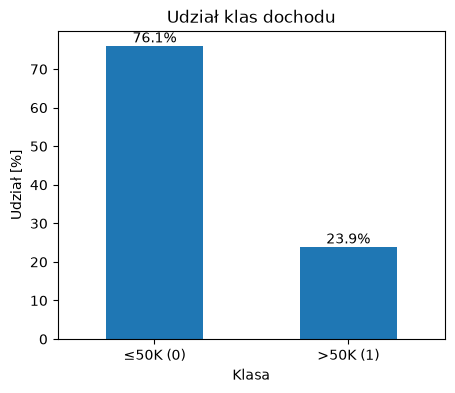

In [8]:
# TODO: udział klas i wykres
class_pct = y.value_counts(normalize=True).sort_index() * 100
print(class_pct.round(2))

ax = class_pct.plot.bar(figsize=(5, 4))
ax.set_xticklabels(["≤50K (0)", ">50K (1)"], rotation=0)
ax.set_title("Udział klas dochodu")
ax.set_xlabel("Klasa")
ax.set_ylabel("Udział [%]")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.show()

In [ ]:
assert n_duplicates == 52
assert len(df) == 48790
assert "income" not in df.columns
assert len(y) == len(df) and set(y.unique()) == {0, 1}
assert n_duplicates_no_weight > 1000
assert 23.5 < class_pct[1] < 24.5 and np.isclose(class_pct.sum(), 100)
print("Rozwiązanie poprawne!")

**Odpowiedź:**

- Duplikaty mogą pochodzić z błędów technicznych, lub po prostu dwie osoby mogą być identyczne według cech które są w zbiorze.
- Wiersze różniące się tylko fnlwgt to najprawdopodobniej różne osoby. Waga zależy od stanu zamieszkania i sposobu losowania próby, a tych informacji nie ma w zbiorze.

---

### Klasyfikacja niezbalansowana

Dochód `>50K` ma niecała jedna czwarta osób. Klasy są więc **niezbalansowane** - mamy **klasę większościową** (`<=50K`) i **mniejszościową** (`>50K`). Nie jest to skrajna nierównowaga (np. w wykrywaniu oszustw, czy modelowaniu aktywnosci zwiazkow chemicznych klasa pozytywna to często ułamek procenta), ale wystarczy, żeby najprostsze metryki zaczęły wprowadzać w błąd. Zobaczymy to w części 3.

### Wartości brakujące

Sprawdźmy, gdzie brakuje danych.

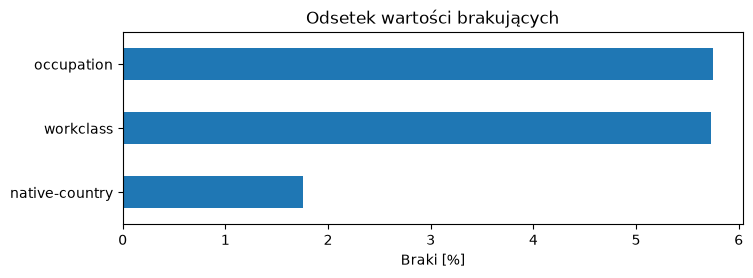

In [9]:
missing_pct = df.isna().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

ax = missing_pct.plot.barh(figsize=(8, 2.5))
ax.set_title("Odsetek wartości brakujących")
ax.set_xlabel("Braki [%]")
ax.invert_yaxis()
plt.show()

Braki dotyczą trzech kolumn kategorycznych i kilku procent wierszy. Kuszące jest uzupełnienie ich modą albo usunięcie wierszy. Zanim to zrobimy, warto sprawdzić, czy brak jest **losowy**. Czasami sam fakt, że wartości brakuje, coś mówi, np. osoba bez podanego zawodu może częściej nie pracować. Nazywa się to **informatywnymi wartościami brakującymi** (*informative missingness*, *Missing Not At Random*, MNAR). Uzupełnienie modą zatarłoby tę informację.

Do eksploracji przyda się funkcja pomocnicza `plot_target_rate`. Dla każdej wartości kolumny rysuje odsetek klasy pozytywnej, a obok liczbę obserwacji. Przerywana linia to odsetek w całych danych.

In [10]:
def plot_target_rate(data, target, column, min_count=50, title=None):
    stats = target.groupby(data[column], observed=True).agg(["mean", "size"])
    stats = stats[stats["size"] >= min_count]

    fig, axes = plt.subplots(1, 2, figsize=(12, 0.35 * len(stats) + 1.5), sharey=True,
                             gridspec_kw={"width_ratios": [2, 1]})
    labels = stats.index.astype(str)
    axes[0].barh(labels, 100 * stats["mean"], color="tab:blue", alpha=0.7)
    axes[0].axvline(100 * target.mean(), color="tab:red", linestyle="--",
                    label=f"całe dane: {100 * target.mean():.1f}%")
    axes[0].set_xlabel("Odsetek klasy pozytywnej [%]")
    axes[0].set_ylabel(column)
    axes[0].legend()
    axes[0].invert_yaxis()
    axes[1].barh(labels, stats["size"], color="tab:gray", alpha=0.7)
    axes[1].set_xlabel("Liczba obserwacji")
    fig.suptitle(title or f"Odsetek klasy pozytywnej w zależności od {column}")
    plt.tight_layout()
    plt.show()

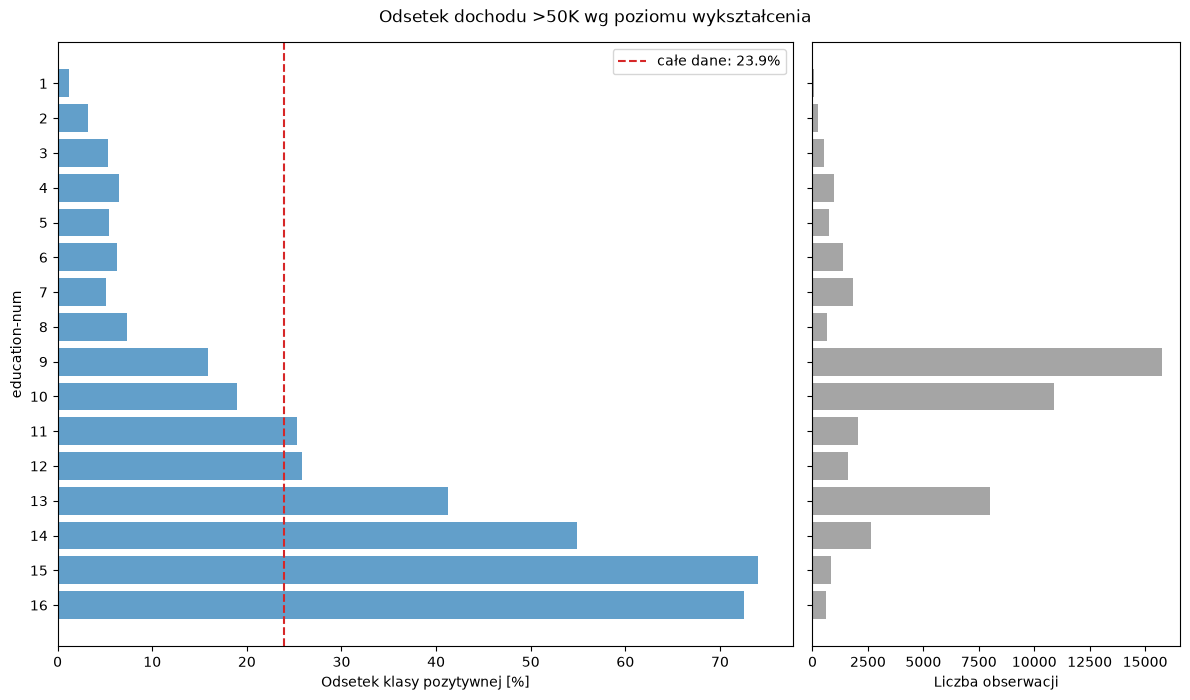

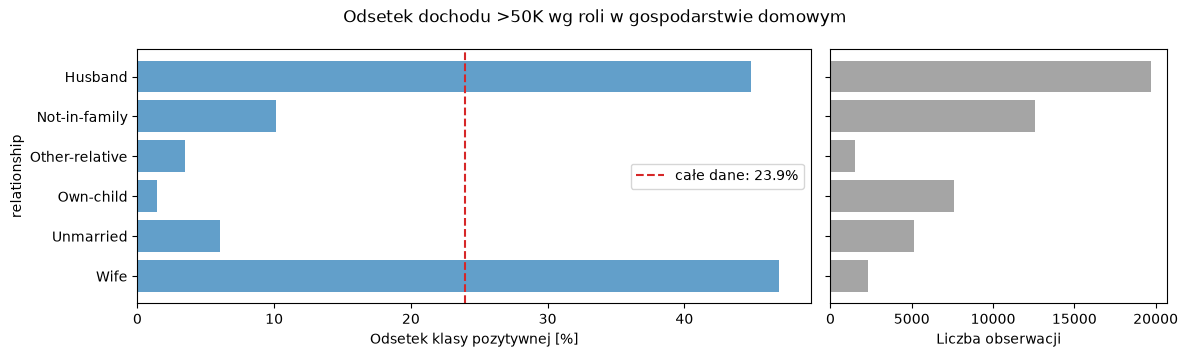

In [11]:
plot_target_rate(df, y, "education-num", title="Odsetek dochodu >50K wg poziomu wykształcenia")
plot_target_rate(df, y, "relationship", title="Odsetek dochodu >50K wg roli w gospodarstwie domowym")

### Zadanie 2 (1 punkt) - informatywne braki i cechy redundantne

1. Dla każdej kolumny z braków (`missing_pct.index`) oblicz odsetek klasy pozytywnej osobno dla wierszy, w których wartość **jest obecna**, i tych, w których jej **brakuje**. Zapisz wynik w `DataFrame` `mnar_rates` z indeksem będącym nazwami kolumn i kolumnami `"present"` oraz `"missing"`.
2. Sprawdź, czy `education` i `education-num` niosą tę samą informację: zapisz w `education_is_redundant` wartość `True`, jeżeli każdej wartości `education` odpowiada dokładnie jedna wartość `education-num` (przyda się `.groupby()` i `.nunique()`).
3. Odpowiedz:
   - w których kolumnach brak jest informatywny? Co by się stało, gdybyśmy uzupełnili braki najczęstszą wartością? Co proponujesz zamiast tego?
   - czy kolumny `education` i `education-num` niosą tę samą informację? Którą z nich warto zostawić i dlaczego? Co zakłada zapis wykształcenia jako liczby od 1 do 16?

In [12]:
# TODO: odsetek klasy pozytywnej dla wartości obecnych i brakujących
mnar_rates = pd.DataFrame(
    {
        "present": [y[df[col].notna()].mean() * 100 for col in missing_pct.index],
        "missing": [y[df[col].isna()].mean() * 100 for col in missing_pct.index],
    },
    index=missing_pct.index,
)
print(mnar_rates.round(2))

                present  missing
occupation        24.81     9.43
workclass         24.81     9.47
native-country    23.90    25.67


In [13]:
# TODO: education kontra education-num
education_is_redundant = bool((df.groupby("education")["education-num"].nunique() == 1).all())
print(education_is_redundant)

True


In [14]:
assert isinstance(mnar_rates, pd.DataFrame) and set(mnar_rates.columns) == {"present", "missing"}
assert set(mnar_rates.index) == {"workclass", "occupation", "native-country"}
assert 9 < mnar_rates.loc["occupation", "missing"] < 10.5
assert 24 < mnar_rates.loc["occupation", "present"] < 25.5
assert education_is_redundant is True
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**
- Brak informatywny mamy w kolumnach 'occupation' oraz 'workclass'. Odsetek klasy pozytywnej jest znacznie niższy dla osób z brakami niż dla osób bez braków.
Można by dodać nową etykietę dla tych osób, albo wstawić tam już istniejący zawód, dla którego proporcja klas jest podobna (9.5% pozytywna).
- Tak, niosą tę samą informację. 

---

### Czyszczenie danych i podział na zbiory

Na podstawie EDA usuwamy dwie kolumny:
- `fnlwgt` - to waga próby w spisie, a nie cecha osoby. Mówi, ile osób w populacji reprezentuje dany wiersz, a nie nic o samej osobie,
- `education` - jest w pełni zakodowana w `education-num` (zadanie 2), a wersja liczbowa zachowuje naturalny porządek poziomów wykształcenia.

Braki zostawiamy - obsłużymy je w potoku przetwarzania, inaczej dla każdego modelu.

Podział: 75% danych treningowych, 25% testowych. Przy niezbalansowanych klasach używamy **stratyfikacji** (`stratify=y`): proporcje klas w obu zbiorach są wtedy takie same jak w całych danych. Bez niej przypadkowo mogłoby się okazać, że w teście jest wyraźnie mniej lub więcej klasy pozytywnej. Walidacja skrośna w scikit-learn dla klasyfikacji stosuje stratyfikację domyślnie (`StratifiedKFold`).

In [ ]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=["fnlwgt", "education"])

X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print(f"Zbiór treningowy: {len(X_train)} wierszy, {100 * y_train.mean():.2f}% klasy >50K")
print(f"Zbiór testowy: {len(X_test)} wierszy, {100 * y_test.mean():.2f}% klasy >50K")
print(f"Cechy numeryczne: {numerical_features}")
print(f"Cechy kategoryczne: {categorical_features}")

## Część 3. Metryki klasyfikacji

### Macierz pomyłek

W klasyfikacji binarnej możliwe są 4 sytuacje:
- **True Positive (TP)** - przewidujemy 1, prawdziwa klasa to 1.
- **True Negative (TN)** - przewidujemy 0, prawdziwa klasa to 0.
- **False Positive (FP)** - przewidujemy 1, prawdziwa klasa to 0 (fałszywy alarm, błąd I rodzaju).
- **False Negative (FN)** - przewidujemy 0, prawdziwa klasa to 1 (przeoczenie, błąd II rodzaju).

| | przewidziane 0 | przewidziane 1 |
|---|---|---|
| **prawdziwe 0** | TN | FP |
| **prawdziwe 1** | FN | TP |

### Accuracy, precision, recall, F1

- **dokładność (accuracy)** - jaki ułamek predykcji jest poprawny: $\frac{TP + TN}{TP + TN + FP + FN}$. Intuicyjna, ale przy niezbalansowanych klasach myląca.
- **precyzja (precision)** - jaki ułamek przewidzianych jedynek to naprawdę jedynki: $\frac{TP}{TP + FP}$. Ważna, gdy fałszywe alarmy są kosztowne.
- **czułość (recall)** - jaki ułamek prawdziwych jedynek wykryliśmy: $\frac{TP}{TP + FN}$. Ważna, gdy przeoczenia są kosztowne.
- **F1** - średnia harmoniczna precyzji i czułości: $\frac{2 \cdot precision \cdot recall}{precision + recall}$. Jest wysoka tylko wtedy, gdy obie są wysokie.

### Prawdopodobieństwa i próg

Większość klasyfikatorów zwraca **prawdopodobieństwo** klasy 1 (`.predict_proba(X)[:, 1]`), a klasę uzyskujemy, porównując je z **progiem** - domyślnie 0.5 (`.predict(X)`). Metryki powyżej zależą więc od progu.

### ROC, AUROC i AUPRC

Można też ocenić same prawdopodobieństwa, biorąc pod uwagę wszystkie progi naraz:
- **krzywa ROC** pokazuje czułość (TPR) w funkcji odsetka fałszywych alarmów wśród negatywów (FPR). Pole pod nią to **AUROC**: 0.5 dla modelu 'losowego', 1.0 dla idealnego. Ma wygodną interpretację: to prawdopodobieństwo, że losowo wybrana osoba z klasy 1 dostanie od modelu wyższe prawdopodobieństwo niż losowo wybrana osoba z klasy 0,
- **krzywa precision-recall** pokazuje precyzję w funkcji czułości. Pole pod nią to **AUPRC** (*average precision*). Dla modelu losowego wynosi tyle, ile udział klasy pozytywnej (u nas ok. 0.24), a nie 0.5. AUPRC skupia się na klasie pozytywnej, więc przy silnej nierównowadze jest bardziej wymagające niż AUROC.

### Model bazowy

Zanim zaczniemy, potrzebujemy **modelu bazowego** - najprostszego możliwego modelu, który każdy sensowny model musi pokonać. [`DummyClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html) z `strategy="most_frequent"` zawsze przewiduje najczęstszą klasę.

### Zadanie 3 (1.5 punktu) - funkcja oceny i model bazowy

1. Uzupełnij funkcję `evaluate_model()`:
   - oblicz prawdopodobieństwa klasy 1 dla zbioru treningowego i testowego oraz przewidziane klasy dla zbioru testowego,
   - oblicz AUROC dla zbioru treningowego i testowego, AUPRC dla testowego oraz precyzję, czułość i F1 dla testowego,
   - wypisz metryki w procentach, zaokrąglone do 2 miejsc po przecinku,
   - zwróć słownik z kluczami `"train_auroc"`, `"test_auroc"`, `"test_auprc"`, `"precision"`, `"recall"`, `"f1"`.

   Jeżeli model nigdy nie przewiduje klasy 1, precyzja jest niezdefiniowana. Przekaż wtedy `zero_division=0` do `precision_score()` i `f1_score()`.
2. Wytrenuj `DummyClassifier(strategy="most_frequent")` w zmiennej `dummy`, oceń go i zapisz wynik w słowniku `results` pod kluczem `"Dummy"`. Słownik `results` będziemy rozbudowywać do końca laboratorium o wyniki dla kolejnych modeli.
3. Oblicz dokładność (`accuracy_score`) modelu bazowego na zbiorze testowym i zapisz w `dummy_accuracy`.
4. Uzupełnij funkcję `plot_curves(models, y_test)`, która rysuje obok siebie krzywe ROC i precision-recall na zbiorze testowym dla kilku modeli naraz. `models` to słownik `{nazwa: (model, X_test)}` (osobne `X_test` przydadzą się dla LightGBM). Użyj `RocCurveDisplay.from_estimator()` i `PrecisionRecallDisplay.from_estimator()` z argumentami `name` i `ax`, a dla pierwszego modelu dodaj `plot_chance_level=True`, żeby zaznaczyć poziom modelu losowego. Narysuj krzywe modelu bazowego. Na koniec laboratorium użyjemy tej funkcji do porównania najlepszych modeli.
5. Odpowiedz: jaką dokładność ma model, który nigdy nie przewiduje dochodu `>50K`? Dlaczego AUROC wynosi dokładnie 0.5, a AUPRC ok. 0.24? Jak widać to na wykresach? Dlaczego w tym laboratorium nie będziemy używać dokładności?

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_model(model, X_train, X_test, y_train, y_test):
    # TODO
    metrics = {}
    return metrics


results = {}

# TODO: model bazowy
dummy = None
dummy_accuracy = None

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay


def plot_curves(models, y_test):
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5.5))
    # TODO
    ax_roc.set_title("Krzywa ROC")
    ax_pr.set_title("Krzywa precision-recall")
    plt.tight_layout()
    plt.show()


# TODO: krzywe modelu bazowego

In [ ]:
assert set(results["Dummy"]) == {"train_auroc", "test_auroc", "test_auprc", "precision", "recall", "f1"}
assert results["Dummy"]["test_auroc"] == 0.5
assert results["Dummy"]["precision"] == 0 and results["Dummy"]["recall"] == 0 and results["Dummy"]["f1"] == 0
assert np.isclose(results["Dummy"]["test_auprc"], y_test.mean())
assert 0.75 < dummy_accuracy < 0.77
print("Rozwiązanie poprawne!")

**Odpowiedź:**

// skomentuj tutaj

---

## Część 4. Regresja logistyczna

**Regresja logistyczna** łączy model liniowy z funkcją sigmoidalną, która zamienia wynik na prawdopodobieństwo:

$$P(y = 1 \mid \mathbf{x}) = \sigma(w_0 + \mathbf{w}^T \mathbf{x}) = \frac{1}{1 + e^{-(w_0 + \mathbf{w}^T \mathbf{x})}}$$

Granica decyzyjna przy progu 0.5 to hiperpłaszczyzna $w_0 + \mathbf{w}^T \mathbf{x} = 0$. Wag nie da się wyznaczyć analitycznie - minimalizujemy numerycznie **binarną entropię krzyżową** (*log loss*):

$$\text{BCE} = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log \hat{p}_i + (1 - y_i) \log (1 - \hat{p}_i) \right]$$

W [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) regularyzację L2 kontroluje parametr `C` - **odwrotność** siły regularyzacji (odwrotnie niż `alpha` w ridge). 

Waga cechy ma interpretację podobną jak w regresji liniowej logarytmu ceny: wzrost cechy o 1 (u nas o 1 odchylenie standardowe) **mnoży szanse** $\frac{p}{1-p}$ przez $e^{w}$ (iloraz szans, *odds ratio*).

### Ważenie klas

W funkcji kosztu sumujemy błędy po wszystkich przykładach, więc klasa większościowa ją dominuje. **Ważenie klas** mnoży błędy każdej klasy przez wagę. Przy `class_weight="balanced"` wagi są odwrotnie proporcjonalne do liczności klas, $w_k = \frac{N}{K \cdot N_k}$, więc obie klasy mają łącznie taki sam wpływ na koszt.

### Przetwarzanie danych w potoku

Jak w laboratorium 1 łączymy przetwarzanie i model w `Pipeline`, a `ColumnTransformer` kieruje cechy numeryczne i kategoryczne do osobnych kroków. Dla braków w cechach kategorycznych porównamy dwa podejścia z zadania 2: **modę** i **osobną kategorię `"Brak"`**.

### Zadanie 4 (1.5 punktu) - regresja logistyczna

1. Uzupełnij funkcję `make_linear_preprocessor(cat_imputer)`, która zwraca `ColumnTransformer` (z `verbose_feature_names_out=False`) z dwoma krokami:
   - `"num"` - `StandardScaler` dla `numerical_features` (cechy numeryczne nie mają braków),
   - `"cat"` - `Pipeline` z krokami `"imputer"` (przekazany `cat_imputer`) oraz `"onehot"` (`OneHotEncoder` z `handle_unknown="infrequent_if_exist"`, `min_frequency=0.01`, `sparse_output=False`) dla `categorical_features`.
2. Zbuduj i wytrenuj trzy potoki z `LogisticRegression(solver="newton-cholesky", max_iter=1000)`, oceń je i zapisz wyniki w `results`:
   - `log_reg_mode` - braki kategoryczne uzupełniane modą (`SimpleImputer(strategy="most_frequent")`), klucz `"LR moda"`,
   - `log_reg` - braki jako kategoria `"Brak"` (`SimpleImputer(strategy="constant", fill_value="Brak")`), klucz `"LR"`,
   - `log_reg_balanced` - jak `log_reg`, ale z `class_weight="balanced"`, klucz `"LR balanced"`.
3. Narysuj obok siebie macierze pomyłek modeli `log_reg` i `log_reg_balanced` na zbiorze testowym (`ConfusionMatrixDisplay.from_estimator()` z argumentem `ax`).
4. Sprawdź, co imputacja robi z osobami z brakami. Dla wierszy zbioru testowego z brakiem w `workclass` lub `occupation` oblicz rzeczywisty odsetek `>50K` oraz średnie przewidywane prawdopodobieństwo `>50K` modeli `log_reg_mode` i `log_reg` (wszystko w procentach). Zapisz wynik w `pd.Series` `missing_check` z indeksem `"rzeczywisty"`, `"LR moda"`, `"LR"`.
5. Odpowiedz:
   - czy osobna kategoria `"Brak"` pomogła względem mody? Porównaj AUROC i AUPRC na całym zbiorze testowym z `missing_check`. Dlaczego różnica w AUROC jest mała, a w `missing_check` wyraźna? Czy to zgodne z zadaniem 2?
   - jak ważenie klas zmieniło precyzję, czułość i F1, a jak AUROC? Dlaczego AUROC prawie się nie zmienia?

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_linear_preprocessor(cat_imputer):
    # TODO
    return None


# TODO: trzy modele regresji logistycznej
log_reg_mode = None
log_reg = None
log_reg_balanced = None

# TODO: sprawdzenie na wierszach z brakami
missing_check = None

# TODO: macierze pomyłek

In [ ]:
assert isinstance(log_reg[0], ColumnTransformer) and isinstance(log_reg[-1], LogisticRegression)
assert log_reg_balanced[-1].class_weight == "balanced"
assert "workclass_Brak" in log_reg[0].get_feature_names_out()
assert 0.9 < results["LR"]["test_auroc"] < 0.92
assert results["LR"]["test_auprc"] > results["LR moda"]["test_auprc"]
assert results["LR balanced"]["recall"] > results["LR"]["recall"] + 0.2
assert results["LR balanced"]["precision"] < results["LR"]["precision"]
assert isinstance(missing_check, pd.Series) and set(missing_check.index) == {"rzeczywisty", "LR moda", "LR"}
assert 8 < missing_check["rzeczywisty"] < 11
assert abs(missing_check["LR"] - missing_check["rzeczywisty"]) < abs(missing_check["LR moda"] - missing_check["rzeczywisty"])
print("Rozwiązanie poprawne!")

**Odpowiedź:**

// skomentuj tutaj

---

## Część 5. Drzewa decyzyjne

**Drzewo decyzyjne** uczy się reguł if/else ułożonych w drzewo binarne: każdy **węzeł** to podział względem jednej cechy i progu (np. `capital-gain <= 7073.5`), a każdy **liść** to decyzja. Drzewo budowane jest zachłannie: w każdym węźle wybieramy podział, który najbardziej zmniejsza **nieczystość** (*impurity*).

Drzewo budowane do czystych liści idealnie „zapamiętuje” zbiór treningowy: ma niskie obciążenie  i bardzo wysoką wariancję. Dlatego wymaga regularyzacji, czyli ograniczenia wzrostu:
- `max_depth` - maksymalna głębokość.
- `min_samples_leaf` - minimalna liczba przykładów w liściu.
- `min_samples_split` - minimalna liczba przykładów w węźle, żeby go dzielić.

### Przetwarzanie danych dla drzew

Drzewa nie potrzebują skalowania cech (porównują cechę z progiem, więc skala nie ma znaczenia). [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) w scikit-learn obsługuje braki w cechach numerycznych, ale nie obsługuje tekstu. Wystarczy jednak zakodować kategorie kolejnymi liczbami całkowitymi (`OrdinalEncoder`). Dla modelu liniowego wprowadzałoby to nieistniejący porządek, ale drzewo kilkoma podziałami potrafi wyodrębnić dowolną kategorię. Braki kodujemy osobną liczbą (`encoded_missing_value=-1`), więc informacja o braku zostaje zachowana.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

tree_preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_features),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-2,
                           encoded_missing_value=-1), categorical_features),
], verbose_feature_names_out=False)

### Drzewo bez regularyzacji

Metody `.get_depth()` i `.get_n_leaves()` zwracają głębokość drzewa i liczbę liści.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree = Pipeline([("prep", tree_preprocessor), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))])
tree.fit(X_train, y_train)
results["Drzewo"] = evaluate_model(tree, X_train, X_test, y_train, y_test)
print(f"Głębokość: {tree[-1].get_depth()}, liście: {tree[-1].get_n_leaves()}")

### Zadanie 5 (1 punkt) - regularyzacja drzewa

1. Dobierz regularyzację drzewa za pomocą `GridSearchCV` w zmiennej `tree_grid`. Model: potok jak `tree` powyżej (`tree_preprocessor` + `DecisionTreeClassifier(random_state=RANDOM_STATE)`). Sprawdź `max_depth` z `[2, 3, 4, 5, 6, 8]` i `min_samples_leaf` z `[10, 50, 100, 200]`. Użyj `scoring="roc_auc"`, `cv=5`, `n_jobs=-1`. Wypisz najlepsze hiperparametry, oceń najlepszy model i zapisz wynik w `results` pod kluczem `"Drzewo tuned"`.
2. Zapisz najlepsze drzewo (sam klasyfikator, ostatni krok potoku) w `best_tree` i wypisz jego głębokość i liczbę liści.
3. Wytrenuj płytkie drzewo `shallow_tree` z `max_depth=3` (w potoku) i narysuj je funkcją `plot_tree()` z czytelnymi nazwami cech (`tree_preprocessor.get_feature_names_out()` z wytrenowanego potoku) i klas, `filled=True`, `impurity=False`, `proportion=True`.
4. Odpowiedz:
   - jak regularyzacja zmieniła rozmiar drzewa i wyniki? Czy drzewo bez regularyzacji było przeuczone - po czym to widać?
   - zinterpretuj pierwsze dwa poziomy płytkiego drzewa. Czy podziały mają sens?

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree

# TODO: GridSearchCV dla drzewa
tree_grid = None
best_tree = None

# TODO: płytkie drzewo i jego wizualizacja
shallow_tree = None

In [ ]:
assert tree_grid.best_params_["model__max_depth"] in [2, 3, 4, 5, 6, 8]
assert results["Drzewo tuned"]["test_auroc"] > results["Drzewo"]["test_auroc"] + 0.05
assert results["Drzewo"]["train_auroc"] > 0.99
assert best_tree.get_n_leaves() < tree[-1].get_n_leaves() / 10
assert shallow_tree[-1].get_depth() == 3
print("Rozwiązanie poprawne!")

**Odpowiedź:**

// skomentuj tutaj

---

## Część 6. Modele zespołowe: Random Forest i boosting

**Uczenie zespołowe** (*ensemble learning*) łączy wiele modeli w jeden, silniejszy:
- **bagging** - wiele modeli uczonych niezależnie na lekko różnych wersjach danych, a ich predykcje uśredniamy, zmniejsza wariancję
- **boosting** - modele uczone sekwencyjnie, każdy poprawia błędy poprzednich, zmniejsza przede wszystkim obciążenie

Drzewa są idealnym kandydatem do budowania modeli zespołowych: są szybkie, mają niskie obciążenie i wysoką wariancję, którą uśrednianie skutecznie zmniejsza.

### Random Forest

**Las losowy** to bagging drzew z dodatkowym losowaniem cech:
1. każde drzewo uczy się na **próbce bootstrapowej** - $N$ przykładów wylosowanych ze zwracaniem, średnio ok. 37% przykładów nie trafia do próbki
2. przy każdym podziale drzewo wybiera tylko spośród losowego podzbioru cech (domyślnie $\sqrt{D}$), co zwiększa **różnorodność** drzew
3. predykcja lasu to średnia prawdopodobieństw wszystkich drzew.



### Zadanie 6 (0.5 punktu) - Random Forest

1. Wytrenuj Random Forest z 500 drzewami w potoku z `tree_preprocessor` w zmiennej `rf` (`n_jobs=-1`, `random_state=RANDOM_STATE`). Oceń go i zapisz wynik pod kluczem `"Random Forest"` w słowniku `results`.
2. Wytrenuj taki sam las, ale z `min_samples_leaf=5`, w zmiennej `rf_leaf5`. Zapisz wynik pod kluczem `"Random Forest leaf=5"`.
3. Wytrenuj las z `class_weight="balanced_subsample"` (i `min_samples_leaf=5`) w zmiennej `rf_balanced`. Zapisz wynik pod kluczem `"Random Forest balanced"`.
4. Odpowiedz:
   - jak las wypada na tle pojedynczego drzewa (bez regularyzacji i po strojeniu)?
   - AUROC treningowe pierwszego lasu wynosi prawie 100%, a testowe ok. 90%. Skąd tak wysoki wynik na treningu? Czy las jest przeuczony w takim samym stopniu jak pojedyncze drzewo bez regularyzacji?
   - jak ważenie klas wpłynęło na precyzję i czułość? Porównaj z regresją logistyczną.

**Dlaczego w `rf_balanced` ograniczamy liście (`min_samples_leaf=5`)?** Drzewo bez ograniczeń dzieli dane tak długo, aż każdy liść jest **czysty**, czyli zawiera przykłady tylko jednej klasy. Taki liść zawsze zwraca prawdopodobieństwo 0 albo 1. Wagi klas działają tak, że przy liczeniu proporcji w liściu każdy przykład klasy mniejszościowej liczy się kilka razy mocniej. W czystym liściu nie ma jednak czego ważyć: trzy osoby z `>50K`, nawet z podwójną wagą, to nadal 100% klasy 1. Wagi prawie nic więc nie zmieniają.

Gdy liść musi mieć co najmniej 5 przykładów, często zawiera obie klasy, np. 2 osoby z `>50K` i 3 z `<=50K`. Bez wag liść zwraca prawdopodobieństwo $2/5 = 0.4$. Przy `balanced` klasa `>50K` (24% danych) dostaje wagę ok. 2.1, a klasa `<=50K` ok. 0.66, więc ten sam liść zwraca $\frac{2 \cdot 2.1}{2 \cdot 2.1 + 3 \cdot 0.66} \approx 0.68$ i przy progu 0.5 zmienia decyzję. Dopiero wtedy wagi klas działają w lesie tak samo jak w regresji logistycznej.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# TODO: trzy lasy losowe
rf = None
rf_leaf5 = None
rf_balanced = None

In [ ]:
assert rf[-1].n_estimators == 500 and rf_leaf5[-1].min_samples_leaf == 5
assert rf_balanced[-1].class_weight == "balanced_subsample"
assert results["Random Forest"]["train_auroc"] > 0.99
assert results["Random Forest"]["test_auroc"] > results["Drzewo"]["test_auroc"] + 0.1
assert results["Random Forest leaf=5"]["test_auroc"] > results["Random Forest"]["test_auroc"]
assert results["Random Forest balanced"]["recall"] > results["Random Forest leaf=5"]["recall"]
print("Rozwiązanie poprawne!")

**Odpowiedź:**

// skomentuj tutaj

---

### Jak dobrać liczbę drzew? Błąd out-of-bag

Liczba drzew `n_estimators` to jedyny hiperparametr lasu, którego nie trzeba się obawiać: doodawanie drzew nie prowadzi do przeuczenia, tylko zmniejsza losowe wahania średniej. Wynik rośnie coraz wolniej, aż się wypłaszcza, a każde nowe drzewo kosztuje czas. Chcemy więc znaleźć moment, od którego dalsze drzewa przestają pomagać. Do tego potrzebujemy oceny modelu dla różnych liczb drzew - i las daje ją prawie za darmo.

**Skąd ocena „za darmo”?** Każde drzewo uczy się na próbce bootstrapowej, czyli $N$ przykładach wylosowanych ze zwracaniem. Część przykładów trafia do próbki kilka razy, a część nie trafia wcale - to przykłady **out-of-bag (OOB)** dla tego drzewa. Ile ich jest? W jednym losowaniu konkretny przykład **nie** zostanie wybrany z prawdopodobieństwem $1 - \frac{1}{N}$. Losowań jest $N$ i są niezależne, więc przykład nie trafi do próbki z prawdopodobieństwem $\left(1 - \frac{1}{N}\right)^N \approx e^{-1} \approx 0.37$ (przybliżenie jest bardzo dokładne już dla $N$ rzędu setek, a u nas $N \approx 36$ tys.). Dla tego drzewa są one jak zbiór walidacyjny: nigdy ich nie widziało.

Każde drzewo losuje swoją próbkę niezależnie, więc przy 500 drzewach każdy przykład treningowy jest OOB średnio dla $500 \cdot 0.37 \approx 185$ z nich. Jeżeli dla każdego przykładu uśrednimy predykcje **tylko tych drzew, które go nie widziały**, dostaniemy uczciwe predykcje dla całego zbioru treningowego, podobne do tych z walidacji skrośnej, ale bez trenowania modelu wiele razy. Na ich podstawie liczymy **OOB AUROC**. Jest on nieco pesymistyczny (każdą predykcję wystawia tylko ok. 37% drzew lasu), ale wystarczy do porównań.

**Jak działa kod poniżej:**
- `oob_score=True` - las zapisuje predykcje OOB w atrybucie `.oob_decision_function_` (prawdopodobieństwa obu klas dla każdego przykładu treningowego),
- `warm_start=True` - po zwiększeniu `n_estimators` kolejne wywołanie `.fit()` **dokłada** nowe drzewa do istniejących, zamiast uczyć las od nowa, więc krzywą dla 10, 25, ..., 500 drzew liczymy kosztem jednego lasu z 500 drzewami,
- `np.nan_to_num()` - przy bardzo małej liczbie drzew niektóre przykłady trafiły do próbek wszystkich drzew, więc nie mają predykcji OOB (NaN); zamieniamy je na 0.

Na wykresie zobaczysz, że OOB AUROC szybko rośnie przy pierwszych kilkudziesięciu drzewach, a od ok. 100-200 drzew prawie się nie zmienia. 500 drzew w zadaniu 6 to więc bezpieczny wybór: więcej nie zaszkodzi, ale też już nie pomoże.

In [ ]:
X_train_tree = tree_preprocessor.fit_transform(X_train)
rf_oob = RandomForestClassifier(min_samples_leaf=5, oob_score=True, warm_start=True, n_jobs=-1,
                                random_state=RANDOM_STATE)
n_trees_list = [10, 25, 50, 100, 200, 300, 500]
oob_auroc = []
for n_trees in n_trees_list:
    rf_oob.set_params(n_estimators=n_trees)
    rf_oob.fit(X_train_tree, y_train)
    oob_auroc.append(roc_auc_score(y_train, np.nan_to_num(rf_oob.oob_decision_function_[:, 1])))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(n_trees_list, oob_auroc, marker="o")
ax.set_title("Random Forest: AUROC out-of-bag w funkcji liczby drzew")
ax.set_xlabel("Liczba drzew")
ax.set_ylabel("OOB AUROC")
plt.show()

### Boosting i LightGBM

**Gradient boosting** uczy drzewa sekwencyjnie: każde kolejne drzewo przewiduje ujemny gradient funkcji kosztu względem aktualnej predykcji zespołu. Predykcja to suma drzew przemnożonych przez **współczynnik uczenia** $\eta$:

$$F_M(x) = F_0(x) + \eta \sum_{m=1}^{M} f_m(x)$$

Drzewa w boostingu są płytkie (słabe modele), a siła bierze się z ich sumy. W przeciwieństwie do lasu więcej drzew **może** prowadzić do przeuczenia, a liczba drzew i $\eta$ są silnie powiązane.

Użyjemy [LightGBM](https://lightgbm.readthedocs.io/en/stable/), jednej z najszybszych implementacji. Obsługuje on natywnie braki i cechy kategoryczne typu `category` z Pandasa, więc nie wymaga żadnego przetwarzania - wystarczy zmienić typ kolumn. Kategorie ustalamy na zbiorze treningowym, żeby oba zbiory miały ten sam słownik.

Ważne hiperparametry `LGBMClassifier`:
- `n_estimators`, `learning_rate` - liczba drzew i współczynnik uczenia,
- `num_leaves`, `min_child_samples` - złożoność pojedynczego drzewa,
- `subsample`, `colsample_bytree` - losowanie wierszy i cech dla każdego drzewa (jak w lesie losowym).

In [ ]:
def to_lightgbm(X, reference):
    X = X.copy()
    for col in categorical_features:
        X[col] = pd.Categorical(X[col], categories=reference[col].dropna().unique())
    return X


X_train_lgbm = to_lightgbm(X_train, X_train)
X_test_lgbm = to_lightgbm(X_test, X_train)
X_train_lgbm.dtypes

### Zadanie 7 (1 punkt) - LightGBM

1. Wytrenuj `LGBMClassifier` z domyślnymi hiperparametrami w zmiennej `lgbm` na `X_train_lgbm` (`random_state=RANDOM_STATE`, `verbose=-1`). Oceń go na `X_train_lgbm`, `X_test_lgbm` i zapisz wynik pod kluczem `"LightGBM"`.
2. Dobierz hiperparametry za pomocą `RandomizedSearchCV` w zmiennej `lgbm_search`:
   - przestrzeń: `lgbm_param_distributions` poniżej w komórce z kodem
   - model bazowy: `LGBMClassifier(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)`
   - `n_iter=20`, `scoring="roc_auc"`, `cv=3`, `n_jobs=-1`, `random_state=RANDOM_STATE`.

   Zmierz czas przeszukiwania (`time.perf_counter()`) w `lgbm_search_time`. Wypisz najlepsze hiperparametry, oceń najlepszy model i zapisz wynik pod kluczem `"LightGBM tuned"`.
3. Narysuj posortowane wyniki walidacji (`mean_test_score` z `cv_results_`) wszystkich prób jako wykres słupkowy, z poziomą linią dla wyniku domyślnych hiperparametrów (`cross_val_score` z tym samym `cv=3`).
4. Odpowiedz: jak LightGBM wypada na tle lasu i regresji logistycznej? Czy strojenie wyraźnie poprawiło wynik? Jak bardzo wrażliwy jest model na hiperparametry, sądząc po wykresie?

Nie zdziw się, jeżeli strojenie nie poprawi wyniku. To też jest wynik, który trzeba umieć zinterpretować.

In [ ]:
import time

from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, cross_val_score

lgbm_param_distributions = {
    "n_estimators": randint(100, 1000),
    "learning_rate": loguniform(0.005, 0.3),
    "num_leaves": randint(4, 128),
    "min_child_samples": randint(5, 200),
    "subsample": uniform(0.5, 0.5),  # [0.5, 1.0]
    "colsample_bytree": uniform(0.1, 0.9),  # [0.1, 1.0]
}

# TODO: LightGBM z domyślnymi hiperparametrami
lgbm = None

# TODO: RandomizedSearchCV (z pomiarem czasu)
lgbm_search = None
lgbm_search_time = None

# TODO: wykres wyników prób

In [ ]:
assert isinstance(lgbm, LGBMClassifier)
assert results["LightGBM"]["test_auroc"] > results["Random Forest leaf=5"]["test_auroc"]
assert results["LightGBM"]["test_auroc"] > results["LR"]["test_auroc"] + 0.01
assert isinstance(lgbm_search, RandomizedSearchCV) and len(lgbm_search.cv_results_["params"]) == 20
assert lgbm_search.scoring == "roc_auc" and lgbm_search_time > 0
assert results["LightGBM tuned"]["test_auroc"] > 0.92
print("Rozwiązanie poprawne!")

**Odpowiedź:**

// skomentuj tutaj

---

## Część 7. Dobór progu decyzyjnego

Domyślny próg 0.5 to naturalny punkt wyjścia: przypisujemy klasę 1, gdy model uznaje ją za bardziej prawdopodobną niż klasę 0. Ten próg nie bierze jednak pod uwagę ani nierównowagi klas, ani tego, że fałszywe alarmy mieć w naszym problemie różne koszty. Zmieniając go, przesuwamy kompromis między precyzją a czułością:
- **niższy próg** - więcej przykładów uznajemy za klasę 1, więc czułość rośnie, a precyzja spada.
- **wyższy próg** - odwrotnie.

Próg jest hiperparametrem, więc - tak jak inne - **nie mozna** go dobierać na zbiorze testowym. [`TunedThresholdClassifierCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html) dobiera go walidacją skrośną na zbiorze treningowym, maksymalizując wybraną metrykę (np. F1), a potem trenuje model na całym zbiorze treningowym. Można też maksymalizować własną metrykę kosztu, jeżeli znamy koszty fałszywych alarmów i przeoczeń - zobacz [przykład w dokumentacji scikit-learn](https://scikit-learn.org/stable/auto_examples/model_selection/plot_cost_sensitive_learning.html).

Zwróć uwagę, że zmiana progu **nie zmienia** prawdopodobieństw, więc AUROC i AUPRC pozostają takie same - zmieniają się tylko precyzja, czułość i F1.

### Kalibracja prawdopodobieństw

Jeżeli model ma tylko odpowiadać „tak/nie”, kalibracja nie jest konieczna: próg dobrany walidacją skrośną (jak wyżej) zależy wyłącznie od kolejności przykładów, więc dla źle skalibrowanego modelu wyjdzie po prostu inna liczba, a decyzje będą równie dobre. Kalibracja jest potrzebna, gdy chcemy używać samych prawdopodobieństw w praktyce: ustalić próg z kosztów błędów, podać ryzyko konkretnej osoby. Model jest **dobrze skalibrowany**, jeżeli wśród osób, którym przypisuje prawdopodobieństwo ok. 0.3, dochód `>50K` ma rzeczywiście ok. 30%. Sprawdza to **krzywa kalibracji**: dzielimy przykłady na przedziały według przewidywanego prawdopodobieństwa i w każdym porównujemy średnie przewidywanie z rzeczywistym odsetkiem klasy 1. Dla idealnie skalibrowanego modelu punkty leżą na przekątnej.

Regresja logistyczna jest zwykle dobrze skalibrowana, bo minimalizuje log loss. Wagi klas celowo zmieniają rozkład klas, który widzi model, więc psują kalibrację. Gdy jest ona potrzebna, można ją przywrócić, np. za pomocą [`CalibratedClassifierCV`](https://scikit-learn.org/stable/modules/calibration.html).

Random Forest jako prawdopodobieństwo zwraca średni głos drzew, więc jego kalibracja zależy od tego, jak głęboko pozwolimy rosnąć drzewom. Domyślnie (`max_depth=None`, `min_samples_leaf=1`) każde drzewo dzieli dane aż do czystych liści, czyli zapamiętuje swoją próbę bootstrapową, więc las jest **zbyt pewny siebie**: tam, gdzie przewiduje ok. 95%, rzeczywisty odsetek `>50K` wynosi ok. 89%. Z `min_samples_leaf=5` liście uśredniają kilka przykładów i kalibracja jest wyraźnie lepsza. W najwyższym przedziale las lekko zaniża (ok. 88% wobec 93%), bo żeby zwrócić prawdopodobieństwo bliskie 1, prawie wszystkie drzewa musiałyby się zgodzić.

In [ ]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(6, 6))
for name, model, X in [("LR", log_reg, X_test), ("LR balanced", log_reg_balanced, X_test),
                       ("Random Forest", rf, X_test), ("Random Forest leaf=5", rf_leaf5, X_test),
                       ("LightGBM", lgbm, X_test_lgbm)]:
    CalibrationDisplay.from_estimator(model, X, y_test, n_bins=10, strategy="quantile", name=name, ax=ax)
ax.set_title("Krzywe kalibracji na zbiorze testowym")
plt.show()

### Zadanie 8 (1.5 punktu) - tuning progu

1. Dla trzech modeli: `log_reg`, `log_reg_balanced` i `lgbm` (z danymi `X_train_lgbm`/`X_test_lgbm`) dobierz próg maksymalizujący F1 za pomocą `TunedThresholdClassifierCV(model, scoring="f1", cv=5, n_jobs=-1)`. Zapisz modele w słowniku `tuned_models` pod kluczami `"LR"`, `"LR balanced"`, `"LightGBM"`.
2. Zbierz w `DataFrame` `threshold_results` (indeks: nazwy modeli) kolumny: `"threshold"` (najlepszy próg, `.best_threshold_`), `"f1_default"` (F1 na teście przy progu 0.5, z `results`) i `"f1_tuned"` (F1 na teście po tuningu progu).
3. Dla `lgbm` narysuj, jak precyzja, czułość i F1 na zbiorze testowym zmieniają się w funkcji progu (np. dla `np.linspace(0.05, 0.95, 19)`), i zaznacz pionową linią próg wybrany przez `TunedThresholdClassifierCV`.
4. Odpowiedz:
   - czy najlepsze progi są wyższe, czy niższe niż 0.5? Dlaczego dla `LR balanced` próg wychodzi inaczej niż dla `LR`?
   - jak tuning progu zmienił F1? Porównaj zysk z tuningu progu z zyskiem z wag klas (zadanie 4). Co z tego wynika?
   - załóżmy, że przeoczenie osoby z dochodem `>50K` kosztuje 5 razy więcej niż fałszywy alarm. Jaki próg minimalizuje oczekiwany koszt dla dobrze skalibrowanego modelu? Dla którego z trzech modeli możesz go użyć bez zmian, a dla którego nie? (Podpowiedź: krzywe kalibracji.)

In [ ]:
from sklearn.model_selection import TunedThresholdClassifierCV

# TODO: tuning progu dla trzech modeli
tuned_models = {}
threshold_results = None

# TODO: wykres metryk w funkcji progu dla LightGBM

In [ ]:
assert set(tuned_models) == {"LR", "LR balanced", "LightGBM"}
assert isinstance(threshold_results, pd.DataFrame)
assert {"threshold", "f1_default", "f1_tuned"} <= set(threshold_results.columns)
assert threshold_results.loc["LR", "threshold"] < 0.5
assert threshold_results.loc["LR balanced", "threshold"] > threshold_results.loc["LR", "threshold"]
assert threshold_results.loc["LR", "f1_tuned"] > threshold_results.loc["LR", "f1_default"]
assert threshold_results.loc["LightGBM", "f1_tuned"] > threshold_results.loc["LightGBM", "f1_default"]
print("Rozwiązanie poprawne!")

**Odpowiedź:**

// skomentuj tutaj

---

## Część 8. Ważność cech

Poza samym wynikiem chcemy wiedzieć, **na czym** model opiera decyzje: żeby sprawdzić, czy przesłanki mają sens, wykryć wyciek danych albo błąd w przetwarzaniu, a także wtedy, gdy decyzja musi być uzasadniona (np. odmowa kredytu).

Każdy model ma własną miarę ważności:
- **regresja logistyczna** - wartość bezwzględna wag (przy ustandaryzowanych cechach), ale osobno dla każdej kolumny one-hot
- **Random Forest** - **MDI** (*mean decrease in impurity*): łączny spadek nieczystości dzięki podziałom z daną cechą. Jest szybka, ale faworyzuje cechy o wielu unikalnych wartościach i liczona jest na zbiorze treningowym.
- **LightGBM** - `"split"` (liczba podziałów) albo `"gain"` (łączny spadek funkcji kosztu, odpowiednik MDI).

Te miary są nieporównywalne między modelami. Wspólną miarą jest **permutation importance**: losowo permutujemy jedną kolumnę w zbiorze testowym i mierzymy, o ile spada wynik modelu. Jeżeli model z cechy nie korzysta, wynik się nie zmieni. Metoda działa dla dowolnego modelu i liczona jest na surowych kolumnach (przed one-hot), więc wyniki różnych modeli można zestawić obok siebie.

### Zadanie 9 (0.5 punktu) - ważność cech

1. Dla modeli `log_reg`, `rf_leaf5` i `lgbm` oblicz `permutation_importance` na zbiorze testowym (`scoring="roc_auc"`, `n_repeats=5`, `random_state=RANDOM_STATE`, `n_jobs=-1`; dla LightGBM użyj `X_test_lgbm`). Zapisz średnie spadki (`importances_mean`) w `DataFrame` `perm_importances` z indeksem będącym nazwami kolumn `X_test` i kolumnami `"LR"`, `"Random Forest"`, `"LightGBM"`.
2. Narysuj `perm_importances` posortowane według LightGBM jako poziomy wykres słupkowy (`.plot.barh()`).
3. Narysuj obok MDI lasu (`rf_leaf5[-1].feature_importances_`) i gain LightGBM (`lgbm.booster_.feature_importance(importance_type="gain")`, znormalizowany do sumy 1).
4. Odpowiedz:
   - które cechy są najważniejsze i czy ma to sens? Czy modele są zgodne?
   - czym różni się ranking MDI od permutation importance? Która cecha zyskuje w MDI i dlaczego?
   - `sex` i `race` to cechy wrażliwe. Jak mocno korzystają z nich modele? Czy usunięcie tych kolumn wystarczy, żeby model ich „nie znał”? (Podpowiedź: zadanie 2, `relationship`.)

In [ ]:
from sklearn.inspection import permutation_importance

# TODO: permutation importance dla trzech modeli
perm_importances = None

# TODO: wykresy

In [ ]:
assert isinstance(perm_importances, pd.DataFrame)
assert set(perm_importances.columns) == {"LR", "Random Forest", "LightGBM"}
assert set(perm_importances.index) == set(X_test.columns)
assert perm_importances["LightGBM"].idxmax() in {"capital-gain", "age", "relationship", "marital-status"}
assert perm_importances.loc["capital-gain"].min() > 0.02
print("Rozwiązanie poprawne!")

**Odpowiedź:**

// skomentuj tutaj

---

## Porównanie modeli

Zbierzmy wyniki wszystkich modeli. Dla modeli, których próg dobraliśmy w części 7, `results` zawiera wyniki przy progu 0.5.

In [ ]:
results_df = pd.DataFrame(results).T.sort_values("test_auprc")
display(results_df.mul(100).round(2))

ax = results_df[["test_auroc", "test_auprc"]].plot.barh(figsize=(9, 6))
ax.set_title("Porównanie modeli na zbiorze testowym")
ax.set_xlabel("Wartość metryki")
ax.set_xlim(0.2, 1)
plt.show()

Krzywe ROC i precision-recall wybranych modeli pozwalają porównać je przy wszystkich progach naraz. Zwróć uwagę, że przy wysokiej czułości precyzja wszystkich modeli spada w stronę 0.24, czyli poziomu modelu losowego.

In [ ]:
plot_curves(
    {
        "Drzewo": (tree, X_test),
        "LR": (log_reg, X_test),
        "Random Forest leaf=5": (rf_leaf5, X_test),
        "LightGBM": (lgbm, X_test_lgbm),
    },
    y_test,
)

## Podsumowanie (1 punkt)

Odpowiedz krótko:
- Który model wybrałbyś do zastosowania i z jakim progiem? Od czego zależy wybór progu w praktyce?
- Które z technik dla niezbalansowanych klas (wagi klas, tuning progu) okazały się przydatne na tych danych, a które nie? Dlaczego?
- Jak zmieniłyby się Twoje wnioski o technikach dla niezbalansowanych klas, gdyby klasa pozytywna stanowiła nie 24%, a 1-2% danych?
- Ile pracy w przygotowanie danych wymagał każdy model (regresja logistyczna, drzewa, LightGBM) i jak przełożyło się to na wyniki?

**Odpowiedź:**

// skomentuj tutaj